# 05 — Backtest, costs, portfolio and risk / 回測、成本、配置與風險

**EN** Same protocol for every book: 7 staggered tranches, exact funding settlements, taker fee + half-spread + sqrt impact. The deployed ridge book is re-simulated live and compared with the report.

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 所有策略同一協定：7 個錯開的部位批次、逐筆資金費結算、taker 手續費 + 半價差 + 平方根衝擊成本。這裡會即時重跑 Ridge 回測並與報告比對。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

In [2]:
# Reported metrics of every book / 各策略的回測指標
bm = pd.read_csv("reports/backtest_metrics.csv")
display(bm[["strategy", "sharpe", "gross_sharpe", "max_drawdown", "turnover_annual", "breakeven_bp_per_leg", "cost_regime"]])

,strategy,sharpe,gross_sharpe,max_drawdown,turnover_annual,breakeven_bp_per_leg,cost_regime
0,ridge EW,-0.1878,-0.0606,0.4853,44.0849,-4.3420,hard floor
1,ridge inverse-vol,0.1023,0.2457,0.3968,46.9209,15.4117,NaN
2,rule EW,0.4671,0.6511,0.3645,50.5389,33.9523,comfortable
3,rule inverse-vol,0.8277,1.0962,0.2671,55.2938,38.1659,NaN
4,EW universe (long-only),0.0419,0.0512,0.7849,7.5205,53.0950,NaN
5,ridge EW + vol target,-0.1828,-0.0214,0.3376,40.0199,-1.1897,NaN
6,ridge EW + vol target + kill switch,-0.1462,0.0267,0.2019,24.4027,1.3633,NaN
7,rule EW + vol target,0.3921,0.6006,0.3143,48.2902,27.3769,NaN
8,"ridge EW, 1-day delay",-0.1928,-0.0597,0.4390,44.0311,-4.0789,NaN
9,"rule EW, 1-day delay",0.3937,0.5861,0.3810,50.5362,29.1829,NaN


In [3]:
# Live re-simulation of the deployed ridge book (W5 protocol) / 即時重跑部署的 Ridge 策略
from crowding import backtest as bt
from crowding.config import PROCESSED
from crowding.io import load_daily_bars
cfg = yaml.safe_load(open("config/backtest.yaml", encoding="utf-8"))["period"]
feats = pd.read_parquet(PROCESSED / "features.parquet", columns=["date", "symbol", "rvol_20d"])
uni = pd.read_parquet(PROCESSED / "universe.parquet", columns=["date", "symbol", "rank", "mean_qv_30d", "in_universe"])
m = bt.build_market(load_daily_bars(), pd.read_parquet(PROCESSED / "settlements.parquet"),
                    uni[uni["in_universe"]].merge(feats, on=["date", "symbol"], how="left"))
scores = pd.read_parquet("artifacts/predictions/ridge.parquet").rename(columns={"pred": "score"})
daily = bt.run(m, scores[["date", "symbol", "score"]], cfg["start"], cfg["end_exclusive"]).daily
live = bt.metrics(daily)
print(f"net Sharpe live {live['sharpe']:+.3f} vs report {bm.set_index('strategy').loc['ridge EW', 'sharpe']:+.3f}")

net Sharpe live -0.188 vs report -0.188


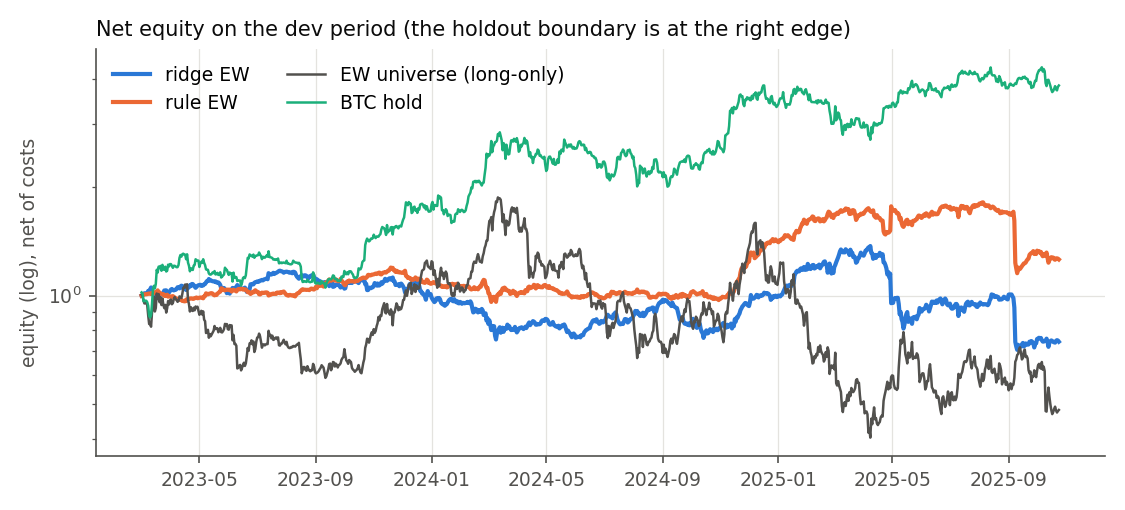

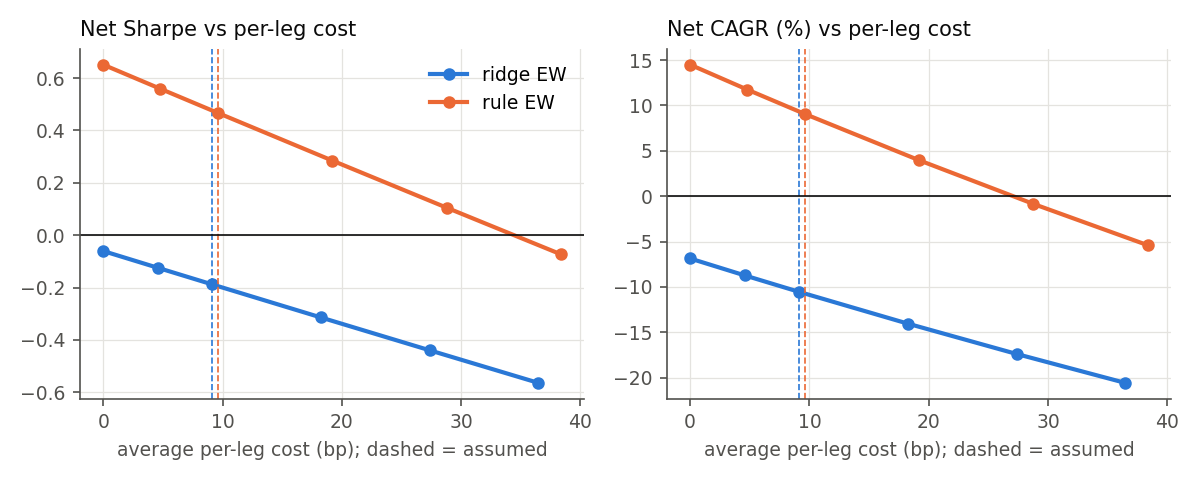

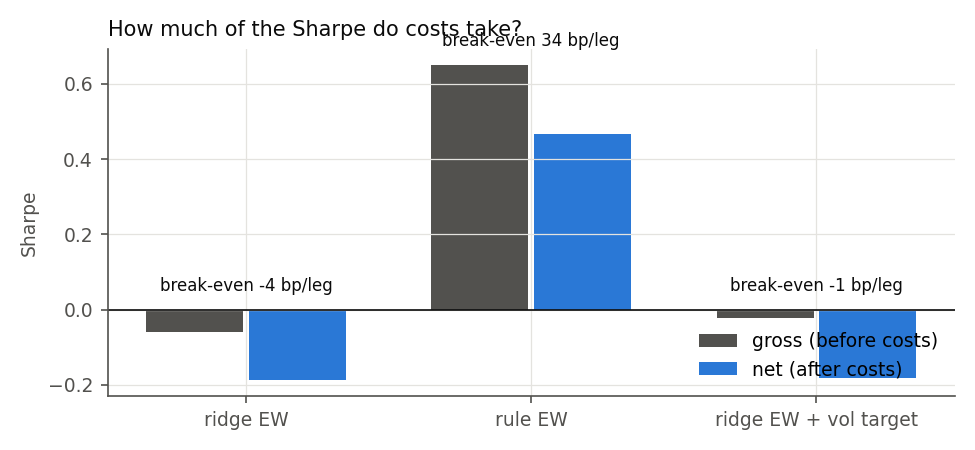

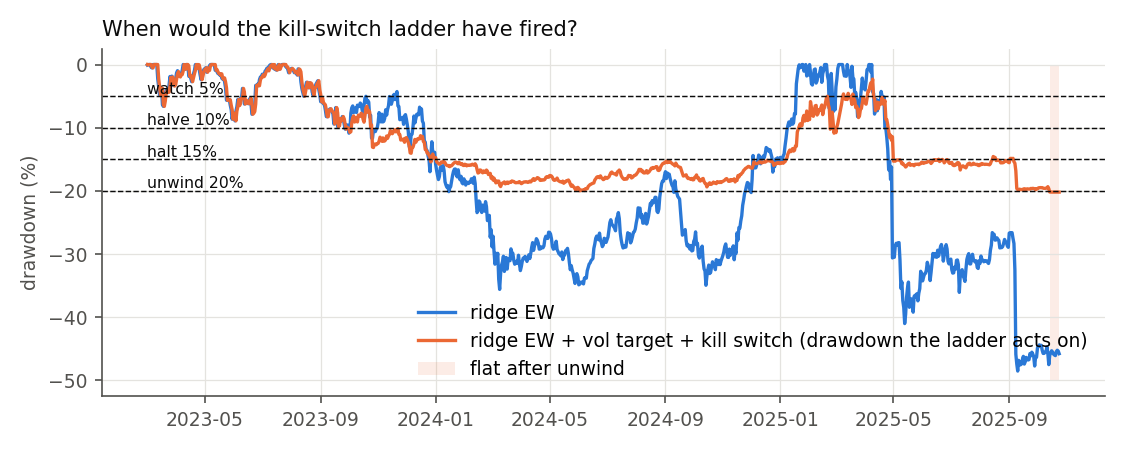

In [4]:
# Equity, cost sweep with break-even, gross vs net, drawdown with kill-switch levels / 權益曲線、成本掃描、毛淨對照、回撤
for f in ("backtest_equity.png", "backtest_cost_sweep.png", "backtest_gross_net.png", "backtest_drawdown.png"):
    show(f)

In [5]:
# Stress episodes and cost stress (spreads x3) / 壓力事件與成本加壓
display(pd.read_csv("reports/backtest_stress.csv"))

,episode,date,strategy,window_return,max_drawdown,worst_day
0,luna,2022-05-09,rule EW (normal costs),-0.0183,0.0334,-0.0168
1,luna,2022-05-09,rule EW (spreads x3),-0.0199,0.0339,-0.0169
2,ftx,2022-11-08,rule EW (normal costs),-0.0123,0.0273,-0.0176
3,ftx,2022-11-08,rule EW (spreads x3),-0.0142,0.0289,-0.0177
4,yen_unwind,2024-08-05,ridge EW (normal costs),0.0735,0.0332,-0.0220
5,yen_unwind,2024-08-05,ridge EW (spreads x3),0.0720,0.0338,-0.0221
6,yen_unwind,2024-08-05,rule EW (normal costs),-0.0291,0.0514,-0.0140
7,yen_unwind,2024-08-05,BTC hold,-0.1306,0.2098,-0.0714
8,liquidation_cascade,2025-10-10,ridge EW (normal costs),-0.0205,0.0564,-0.0322
9,liquidation_cascade,2025-10-10,ridge EW (spreads x3),-0.0219,0.0570,-0.0323
